## 1. Text Preprocessing and Tokenization

In [230]:
# importing all required libs

import re
import pandas as pd
from collections import Counter, defaultdict

In [231]:
# loading the text paragraphs

with open('1.txt', 'r', encoding='utf-8') as file:
    text = file.read()

text

'Mr. and Mrs. Dursley, of number four, Privet Drive, were proud to say that they were perfectly normal, thank you very much. They were the last people you’d expect to be involved in anything strange or mysterious, because they just didn’t hold with such nonsense.\nMr. Dursley was the director of a firm called Grunnings, which made drills. He was a big, beefy man with hardly any neck, although he did have a very large mustache. Mrs. Dursley was thin and blonde and had nearly twice the usual amount of neck, which came in very useful as she spent so much of her time craning over garden fences, spying on the neighbors. The Dursleys had a small son called Dudley and in their opinion there was no finer boy anywhere. \nThe Dursleys had everything they wanted, but they also had a secret, and their greatest fear was that somebody would discover it. They didn’t think they could bear it if anyone found out about the Potters. Mrs. Potter was Mrs. Dursley’s sister, but they hadn’t met for several y

In [232]:
# cleaning the text using regex

cleaned_text = re.sub(r'[^a-zA-Z\s]', '', text)

cleaned_text

'Mr and Mrs Dursley of number four Privet Drive were proud to say that they were perfectly normal thank you very much They were the last people youd expect to be involved in anything strange or mysterious because they just didnt hold with such nonsense\nMr Dursley was the director of a firm called Grunnings which made drills He was a big beefy man with hardly any neck although he did have a very large mustache Mrs Dursley was thin and blonde and had nearly twice the usual amount of neck which came in very useful as she spent so much of her time craning over garden fences spying on the neighbors The Dursleys had a small son called Dudley and in their opinion there was no finer boy anywhere \nThe Dursleys had everything they wanted but they also had a secret and their greatest fear was that somebody would discover it They didnt think they could bear it if anyone found out about the Potters Mrs Potter was Mrs Dursleys sister but they hadnt met for several years in fact Mrs Dursley pretend

In [233]:
# lowercasing all the text

lowercase_text = cleaned_text.lower()

lowercase_text

'mr and mrs dursley of number four privet drive were proud to say that they were perfectly normal thank you very much they were the last people youd expect to be involved in anything strange or mysterious because they just didnt hold with such nonsense\nmr dursley was the director of a firm called grunnings which made drills he was a big beefy man with hardly any neck although he did have a very large mustache mrs dursley was thin and blonde and had nearly twice the usual amount of neck which came in very useful as she spent so much of her time craning over garden fences spying on the neighbors the dursleys had a small son called dudley and in their opinion there was no finer boy anywhere \nthe dursleys had everything they wanted but they also had a secret and their greatest fear was that somebody would discover it they didnt think they could bear it if anyone found out about the potters mrs potter was mrs dursleys sister but they hadnt met for several years in fact mrs dursley pretend

In [234]:
# splitting the text based on spaces to get tokens

tokens = lowercase_text.split()

tokens

['mr',
 'and',
 'mrs',
 'dursley',
 'of',
 'number',
 'four',
 'privet',
 'drive',
 'were',
 'proud',
 'to',
 'say',
 'that',
 'they',
 'were',
 'perfectly',
 'normal',
 'thank',
 'you',
 'very',
 'much',
 'they',
 'were',
 'the',
 'last',
 'people',
 'youd',
 'expect',
 'to',
 'be',
 'involved',
 'in',
 'anything',
 'strange',
 'or',
 'mysterious',
 'because',
 'they',
 'just',
 'didnt',
 'hold',
 'with',
 'such',
 'nonsense',
 'mr',
 'dursley',
 'was',
 'the',
 'director',
 'of',
 'a',
 'firm',
 'called',
 'grunnings',
 'which',
 'made',
 'drills',
 'he',
 'was',
 'a',
 'big',
 'beefy',
 'man',
 'with',
 'hardly',
 'any',
 'neck',
 'although',
 'he',
 'did',
 'have',
 'a',
 'very',
 'large',
 'mustache',
 'mrs',
 'dursley',
 'was',
 'thin',
 'and',
 'blonde',
 'and',
 'had',
 'nearly',
 'twice',
 'the',
 'usual',
 'amount',
 'of',
 'neck',
 'which',
 'came',
 'in',
 'very',
 'useful',
 'as',
 'she',
 'spent',
 'so',
 'much',
 'of',
 'her',
 'time',
 'craning',
 'over',
 'garden',
 'f

In [235]:
# number of tokens

total_tokens = len(tokens)
total_tokens

272

In [236]:
# number of unique tokens

len(set(tokens))

153

## 2. Lexicon Construction 

In [237]:
# loading all the necessary libs for lexicon

import nltk
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer

nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('wordnet', quiet=True)

True

In [238]:
# initializing lemmatizer

lemmatizer = WordNetLemmatizer()

In [239]:
# selecting tokens for lemmatization

selected_tokens = list(set(tokens))[:30]
selected_tokens

['expect',
 'craning',
 'greatest',
 'the',
 'she',
 'no',
 'pretended',
 'several',
 'even',
 'such',
 'firm',
 'reason',
 'four',
 'undursleyish',
 'their',
 'hold',
 'mixing',
 'made',
 'goodfornothing',
 'fall',
 'but',
 'fear',
 'people',
 'fences',
 'wanted',
 'anyone',
 'him',
 'anywhere',
 'you',
 'was']

In [240]:
# tagging all the tokens

tagged_tokens = pos_tag(selected_tokens)

lexicon = {}
for token, pos in tagged_tokens:
    lemma = lemmatizer.lemmatize(token)
    lexicon[token] = (lemma, pos)

In [241]:
# length of the lexicon

len(lexicon)

30

In [242]:
# analyzing all tokens using the lexicon

token_analysis = []
for token in tokens:
    if token in lexicon:
        lemma, pos = lexicon[token]
        token_analysis.append({'Token': token, 'Lemma': lemma, 'POS': pos})
    else:
        lemma = lemmatizer.lemmatize(token)
        pos_tag_result = pos_tag([token])[0][1]
        token_analysis.append({'Token': token, 'Lemma': lemma, 'POS': pos_tag_result})

df_tokens = pd.DataFrame(token_analysis)
df_tokens

,Token,Lemma,POS
0,mr,mr,NN
1,and,and,CC
2,mrs,mr,NN
3,dursley,dursley,NN
4,of,of,IN
...,...,...,...
267,the,the,DT
268,notebook,notebook,NN
269,in,in,IN
270,his,his,PRP$


## 3. Affix Identification 

In [243]:
# defining suffixes and prefixes

suffixes = ['ing', 'ed', 's', 'es', 'ly', 'ish']
prefixes = ['un', 're', 'in', 'dis']

In [244]:
# frequency analysis

suffix_counts = {suffix: 0 for suffix in suffixes}
prefix_counts = {prefix: 0 for prefix in prefixes}

for token in tokens:
    for suffix in suffixes:
        if token.endswith(suffix) and len(token) > len(suffix):
            suffix_counts[suffix] += 1
    
    for prefix in prefixes:
        if token.startswith(prefix) and len(token) > len(prefix):
            prefix_counts[prefix] += 1

affix_data = []
for suffix, count in suffix_counts.items():
    affix_data.append({'Type': 'Suffix', 'Affix': suffix, 'Frequency': count})
for prefix, count in prefix_counts.items():
    affix_data.append({'Type': 'Prefix', 'Affix': prefix, 'Frequency': count})

df_affixes = pd.DataFrame(affix_data)
df_affixes

,Type,Affix,Frequency
0,Suffix,ing,8
1,Suffix,ed,7
2,Suffix,s,34
3,Suffix,es,1
4,Suffix,ly,3
5,Suffix,ish,1
6,Prefix,un,1
7,Prefix,re,1
8,Prefix,in,1
9,Prefix,dis,1


In [245]:
# importing libs

import matplotlib.pyplot as plt

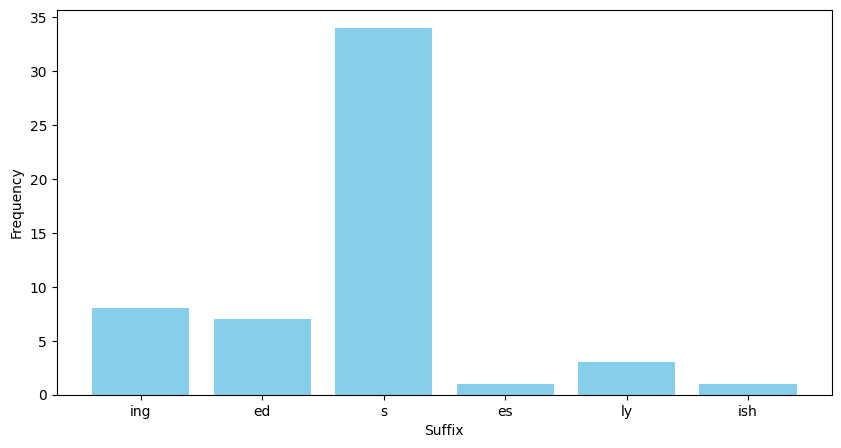

In [246]:
# plotting suffix frequency

plt.figure(figsize=(10, 5))
plt.bar(suffix_counts.keys(), suffix_counts.values(), color='skyblue')
plt.xlabel('Suffix')
plt.ylabel('Frequency')
plt.show()

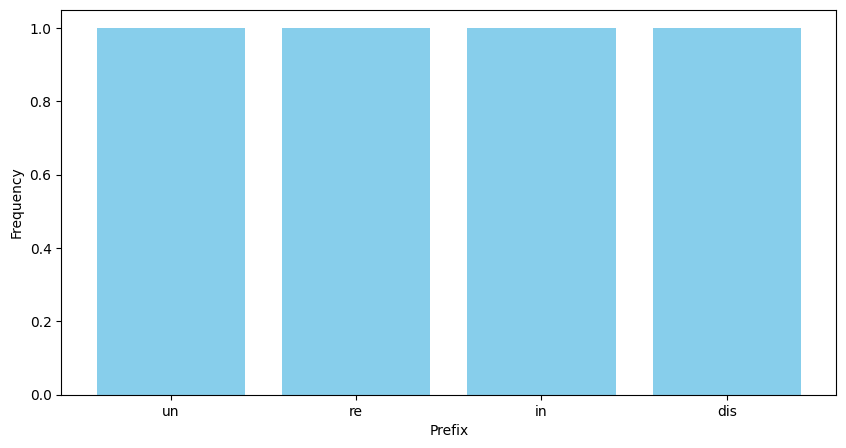

In [247]:
# plotting prefix frequency

plt.figure(figsize=(10, 5))
plt.bar(prefix_counts.keys(), prefix_counts.values(), color='skyblue')
plt.xlabel('Prefix')
plt.ylabel('Frequency')
plt.show()

## 4. Rule-Based Stemmer Implementation

In [248]:
# defining custom functions for rule based stemmer

def rule_based_stemmer(word):
    original_word = word
    
    if len(word) <= 3:
        return word
    
    if word.startswith('un') and len(word) > 4:
        word = word[2:]
    elif word.startswith('re') and len(word) > 4:
        word = word[2:]
    elif word.startswith('in') and len(word) > 4:
        word = word[2:]
    elif word.startswith('dis') and len(word) > 5:
        word = word[3:]
    
    if word.endswith('ingly'):
        word = word[:-5]
    elif word.endswith('ing'):
        if len(word) > 5:
            stem = word[:-3]
            if stem.endswith(stem[-1]) and stem[-1] in 'bdfglmnprst' and len(stem) > 2:
                stem = stem[:-1]
            word = stem
    elif word.endswith('edness'):
        word = word[:-6]
    elif word.endswith('ed'):
        if len(word) > 4:
            stem = word[:-2]
            if stem.endswith(stem[-1]) and stem[-1] in 'bdfglmnprst' and len(stem) > 2:
                stem = stem[:-1]
            word = stem
    elif word.endswith('ies'):
        word = word[:-3] + 'y'
    elif word.endswith('es'):
        if len(word) > 4 and word[-3] in 'sxzo':
            word = word[:-2]
        elif len(word) > 3:
            word = word[:-2]
    elif word.endswith('s') and len(word) > 3:
        if not word.endswith('ss'):
            word = word[:-1]
    elif word.endswith('ly') and len(word) > 4:
        word = word[:-2]
    
    if len(word) < 2:
        return original_word
    
    return word

In [249]:
# running it on our data

stemmed_data = []
for token in tokens:
    stem = rule_based_stemmer(token)
    stemmed_data.append({'Original': token, 'Stem': stem})

df_stemmed = pd.DataFrame(stemmed_data)
df_stemmed.head()

,Original,Stem
0,mr,mr
1,and,and
2,mrs,mrs
3,dursley,dursley
4,of,of


In [250]:
# size of the stemmered df
df_stemmed.shape

(272, 2)

In [251]:
# number of values chnages

change_count = sum(1 for entry in stemmed_data if entry['Original'] != entry['Stem'])
change_count

38

In [252]:
# number of values not changed

unchanged_count = sum(1 for entry in stemmed_data if entry['Original'] == entry['Stem'])
unchanged_count

234

In [253]:
# putting everything in csv to view the full thing

df_stemmed.to_csv('stemmed_output.csv', index=False)
df = pd.DataFrame(entry for entry in stemmed_data if entry['Original'] != entry['Stem'])
df.to_csv('changed_stems.csv', index=False)

## 5. Morphological Rule Extraction

In [254]:
# custom functions for morphological rule based extraction

def form_gerund(root):
    if root.endswith('e') and len(root) > 2:
        return root[:-1] + 'ing'
    elif len(root) > 2 and root[-1] in 'bdfglmnprst' and root[-2] in 'aeiou' and root[-3] not in 'aeiou':
        return root + root[-1] + 'ing'
    else:
        return root + 'ing'

def form_past_tense(root):
    if root.endswith('e'):
        return root + 'd'
    elif root.endswith('y') and len(root) > 2 and root[-2] not in 'aeiou':
        return root[:-1] + 'ied'
    elif len(root) > 2 and root[-1] in 'bdfglmnprst' and root[-2] in 'aeiou' and root[-3] not in 'aeiou':
        return root + root[-1] + 'ed'
    else:
        return root + 'ed'

def form_plural(root):
    if root.endswith(('s', 'x', 'z', 'ch', 'sh')):
        return root + 'es'
    elif root.endswith('y') and len(root) > 1 and root[-2] not in 'aeiou':
        return root[:-1] + 'ies'
    elif root.endswith('f'):
        return root[:-1] + 'ves'
    elif root.endswith('fe'):
        return root[:-2] + 'ves'
    else:
        return root + 's'


In [255]:
# running it on our stemed data

base_words = df['Stem']

transformations = []

for word in base_words:
    transformations.append({
        'Root': word,
        'Gerund': form_gerund(word),
        'Past Tense': form_past_tense(word),
        'Plural': form_plural(word)
    })

df_transformations = pd.DataFrame(transformations)
df_transformations.head()

,Root,Gerund,Past Tense,Plural
0,perfect,perfecting,perfected,perfects
1,volv,volving,volved,volvs
2,anyth,anything,anythed,anyths
3,mysteriou,mysteriouing,mysterioued,mysterious
4,cal,calling,called,cals


## 6. Compound Word Splitting

In [256]:
# defining the morpheme lexicon

morpheme_lexicon = {
    'note', 'book', 'any', 'thing', 'where', 'some', 'body',
}

In [257]:
# defiining the custom functions

def find_all_splits(word, morpheme_lexicon):
    splits = []
    
    for i in range(1, len(word)):
        left = word[:i]
        right = word[i:]
        
        if left in morpheme_lexicon and right in morpheme_lexicon:
            splits.append((left, right))
    
    return splits

def choose_best_split(splits):
    if not splits:
        return None
    
    max_length = 0
    best_split = splits[0]
    
    for split in splits:
        total_length = len(split[0]) + len(split[1])
        if total_length > max_length:
            max_length = total_length
            best_split = split
    
    return best_split

In [258]:
# running it on our tokens

compound_words = tokens

compound_results = []

for word in compound_words:
    all_splits = find_all_splits(word, morpheme_lexicon)
    best_split = choose_best_split(all_splits)
    
    compound_results.append({
        'Compound Word': word,
        'All Possible Splits': all_splits if all_splits else 'None',
        'Best Split': best_split if best_split else 'No valid split'
    })

df_compounds = pd.DataFrame(compound_results)
df_compounds_valid = df_compounds[df_compounds['All Possible Splits'] != 'None']
df_compounds_valid

,Compound Word,All Possible Splits,Best Split
33,anything,"[(any, thing)]","(any, thing)"
129,anywhere,"[(any, where)]","(any, where)"
148,somebody,"[(some, body)]","(some, body)"
268,notebook,"[(note, book)]","(note, book)"


In [259]:
# save it to csv for full view

df_compounds.to_csv('compound_splits.csv', index=False)